In [ ]:
import pandas as pd

df = pd.read_csv("/content/owid-covid-data.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nTop 15 Columns with Missing Values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

Dataset Shape: (44785, 41)

Column Names:
['iso_code', 'continent', 'location', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'new_tests', 'total_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'tests_per_case', 'positive_rate', 'tests_units', 'stringency_index', 'population', 'population_density', 'median_age', 'aged_65_older', 'aged_70_older', 'gdp_per_capita', 'extreme_poverty', 'cardiovasc_death_rate', 'diabetes_prevalence', 'female_smokers', 'male_smokers', 'handwashing_facilities', 'hospital_beds_per_thousand', 'life_expectancy', 'human_development_index']

First 5 Rows:


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,gdp_per_capita,extreme_poverty,cardiovasc_death_rate,diabetes_prevalence,female_smokers,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index
0,AFG,Asia,Afghanistan,2019-12-31,0.0,0.0,NaN,0.0,0.0,NaN,...,1803.987,NaN,597.029,9.59,NaN,NaN,37.746,0.5,64.83,0.498
1,AFG,Asia,Afghanistan,2020-01-01,0.0,0.0,NaN,0.0,0.0,NaN,...,1803.987,NaN,597.029,9.59,NaN,NaN,37.746,0.5,64.83,0.498
2,AFG,Asia,Afghanistan,2020-01-02,0.0,0.0,NaN,0.0,0.0,NaN,...,1803.987,NaN,597.029,9.59,NaN,NaN,37.746,0.5,64.83,0.498
3,AFG,Asia,Afghanistan,2020-01-03,0.0,0.0,NaN,0.0,0.0,NaN,...,1803.987,NaN,597.029,9.59,NaN,NaN,37.746,0.5,64.83,0.498
4,AFG,Asia,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,...,1803.987,NaN,597.029,9.59,NaN,NaN,37.746,0.5,64.83,0.498



Top 15 Columns with Missing Values:


,0
new_tests,29138
new_tests_per_thousand,29138
total_tests,28763
total_tests_per_thousand,28763
tests_per_case,28636
positive_rate,28252
new_tests_smoothed,27217
new_tests_smoothed_per_thousand,27217
tests_units,26411
handwashing_facilities,26127


In [ ]:
countries = [
    "India",
    "United States",
    "United Kingdom",
    "Brazil",
    "Japan"
]

columns_needed = [
    "iso_code", "continent", "location", "date",
    "total_cases", "new_cases", "new_cases_smoothed",
    "total_deaths", "new_deaths", "new_deaths_smoothed",
    "population", "total_cases_per_million",
    "total_deaths_per_million"
]

covid = df.loc[
    df["location"].isin(countries), columns_needed
].copy()

covid["date"] = pd.to_datetime(covid["date"], errors="coerce")
covid = covid.dropna(subset=["date"])

duplicates_removed = covid.duplicated(
    subset=["location", "date"]
).sum()

covid = covid.drop_duplicates(
    subset=["location", "date"]
)

covid = covid.sort_values(["location", "date"]).reset_index(drop=True)

covid["new_cases_per_million_calculated"] = (
    covid["new_cases"] / covid["population"] * 1_000_000
)

covid["new_cases_7day_avg"] = (
    covid.groupby("location")["new_cases"]
    .transform(lambda s: s.rolling(window=7, min_periods=7).mean())
)

covid["new_deaths_7day_avg"] = (
    covid.groupby("location")["new_deaths"]
    .transform(lambda s: s.rolling(window=7, min_periods=7).mean())
)

covid["case_fatality_ratio_pct"] = (
    covid["total_deaths"] / covid["total_cases"] * 100
).where(covid["total_cases"] > 0)

covid.to_csv("COVID19_Cleaned_Selected_Countries.csv", index=False)

print("Original dataset shape:", df.shape)
print("Selected-country dataset shape:", covid.shape)
print("Duplicate country-date records removed:", duplicates_removed)
print("Countries included:", sorted(covid["location"].unique()))
print("Date range:", covid["date"].min().date(), "to", covid["date"].max().date())

print("\nMissing values in selected analysis columns:")
display(covid.isnull().sum().sort_values(ascending=False).head(12))

print("\nSample of cleaned data:")
display(covid.head(10))

print("\nSaved: COVID19_Cleaned_Selected_Countries.csv")


Original dataset shape: (44785, 41)
Selected-country dataset shape: (1320, 17)
Duplicate country-date records removed: 0
Countries included: ['Brazil', 'India', 'Japan', 'United Kingdom', 'United States']
Date range: 2019-12-31 to 2020-09-19

Missing values in selected analysis columns:


,0
case_fatality_ratio_pct,156
new_deaths_7day_avg,37
new_cases_7day_avg,37
new_deaths_smoothed,30
new_cases_smoothed,30
total_cases_per_million,1
total_cases,1
new_cases,1
total_deaths,1
new_cases_per_million_calculated,1



Sample of cleaned data:


,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,population,total_cases_per_million,total_deaths_per_million,new_cases_per_million_calculated,new_cases_7day_avg,new_deaths_7day_avg,case_fatality_ratio_pct
0,BRA,South America,Brazil,2019-12-31,0.0,0.0,NaN,0.0,0.0,NaN,212559409.0,0.0,0.0,0.0,NaN,NaN,NaN
1,BRA,South America,Brazil,2020-01-01,0.0,0.0,NaN,0.0,0.0,NaN,212559409.0,0.0,0.0,0.0,NaN,NaN,NaN
2,BRA,South America,Brazil,2020-01-02,0.0,0.0,NaN,0.0,0.0,NaN,212559409.0,0.0,0.0,0.0,NaN,NaN,NaN
3,BRA,South America,Brazil,2020-01-03,0.0,0.0,NaN,0.0,0.0,NaN,212559409.0,0.0,0.0,0.0,NaN,NaN,NaN
4,BRA,South America,Brazil,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,212559409.0,0.0,0.0,0.0,NaN,NaN,NaN
5,BRA,South America,Brazil,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,212559409.0,0.0,0.0,0.0,NaN,NaN,NaN
6,BRA,South America,Brazil,2020-01-06,0.0,0.0,0.0,0.0,0.0,0.0,212559409.0,0.0,0.0,0.0,0.0,0.0,NaN
7,BRA,South America,Brazil,2020-01-07,0.0,0.0,0.0,0.0,0.0,0.0,212559409.0,0.0,0.0,0.0,0.0,0.0,NaN
8,BRA,South America,Brazil,2020-01-08,0.0,0.0,0.0,0.0,0.0,0.0,212559409.0,0.0,0.0,0.0,0.0,0.0,NaN
9,BRA,South America,Brazil,2020-01-09,0.0,0.0,0.0,0.0,0.0,0.0,212559409.0,0.0,0.0,0.0,0.0,0.0,NaN



Saved: COVID19_Cleaned_Selected_Countries.csv


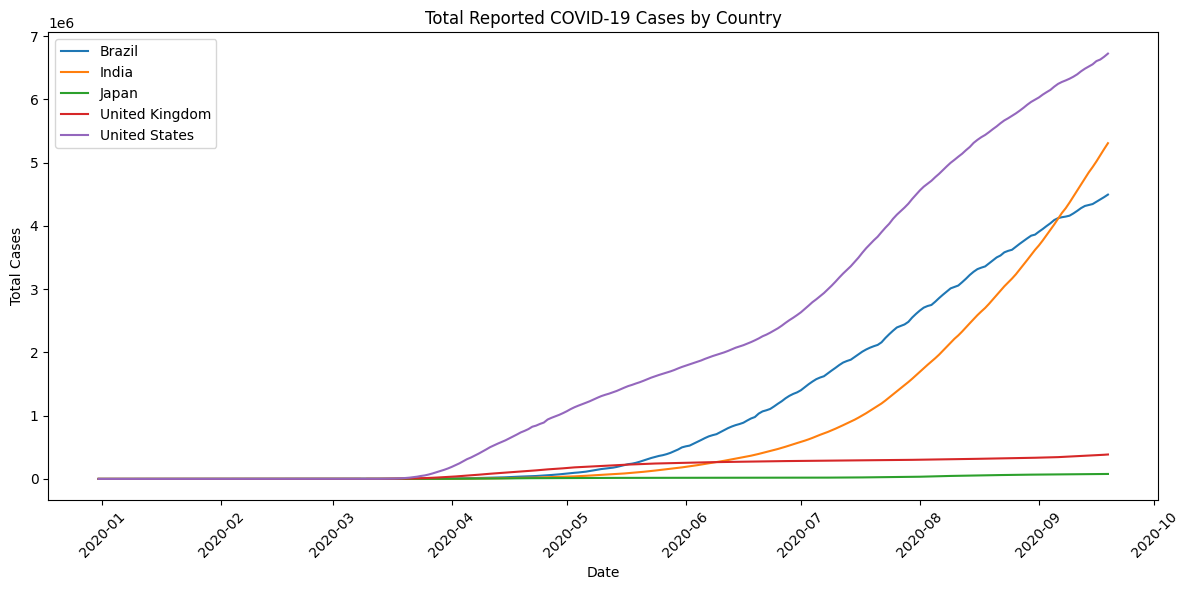

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

covid["date"] = pd.to_datetime(covid["date"])

plt.figure(figsize=(12, 6))
for country, group in covid.groupby("location"):
    plt.plot(group["date"], group["total_cases"], label=country)

plt.title("Total Reported COVID-19 Cases by Country")
plt.xlabel("Date")
plt.ylabel("Total Cases")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

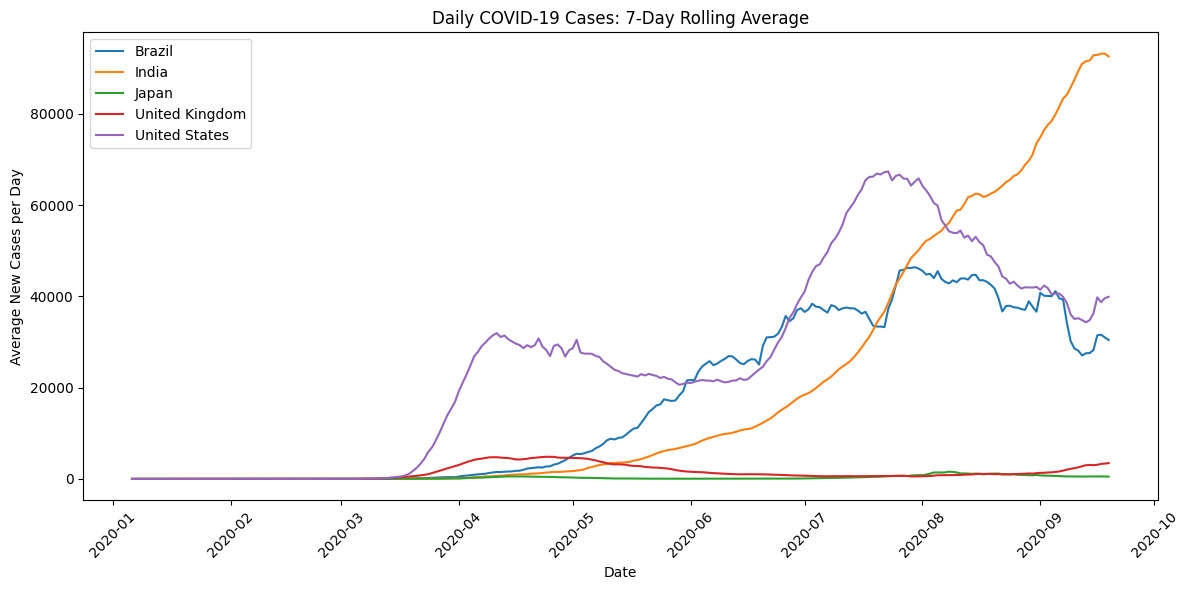

In [ ]:
plt.figure(figsize=(12, 6))
for country, group in covid.groupby("location"):
    plt.plot(group["date"], group["new_cases_7day_avg"], label=country)

plt.title("Daily COVID-19 Cases: 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Average New Cases per Day")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

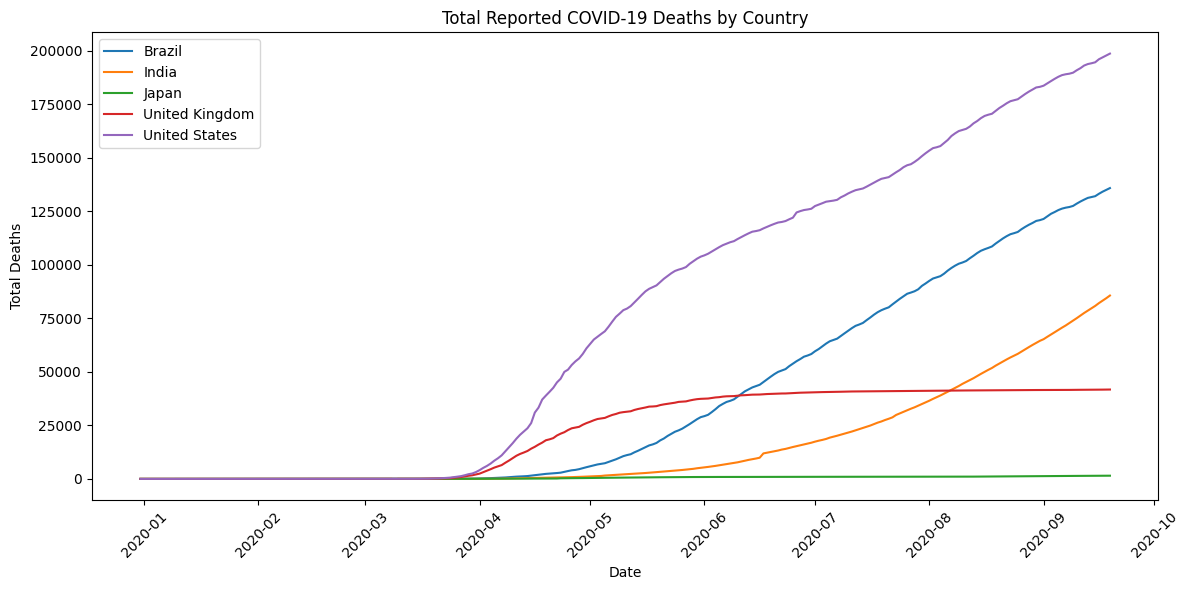

In [ ]:
plt.figure(figsize=(12, 6))
for country, group in covid.groupby("location"):
    plt.plot(group["date"], group["total_deaths"], label=country)

plt.title("Total Reported COVID-19 Deaths by Country")
plt.xlabel("Date")
plt.ylabel("Total Deaths")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

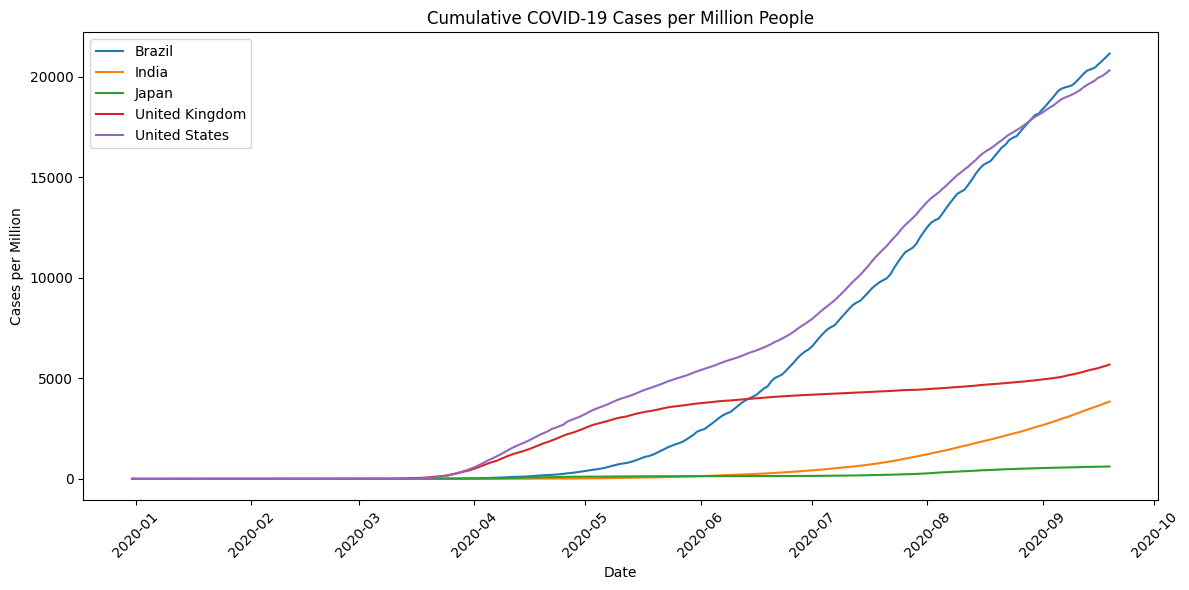

In [ ]:
plt.figure(figsize=(12, 6))
for country, group in covid.groupby("location"):
    plt.plot(group["date"], group["total_cases_per_million"], label=country)

plt.title("Cumulative COVID-19 Cases per Million People")
plt.xlabel("Date")
plt.ylabel("Cases per Million")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

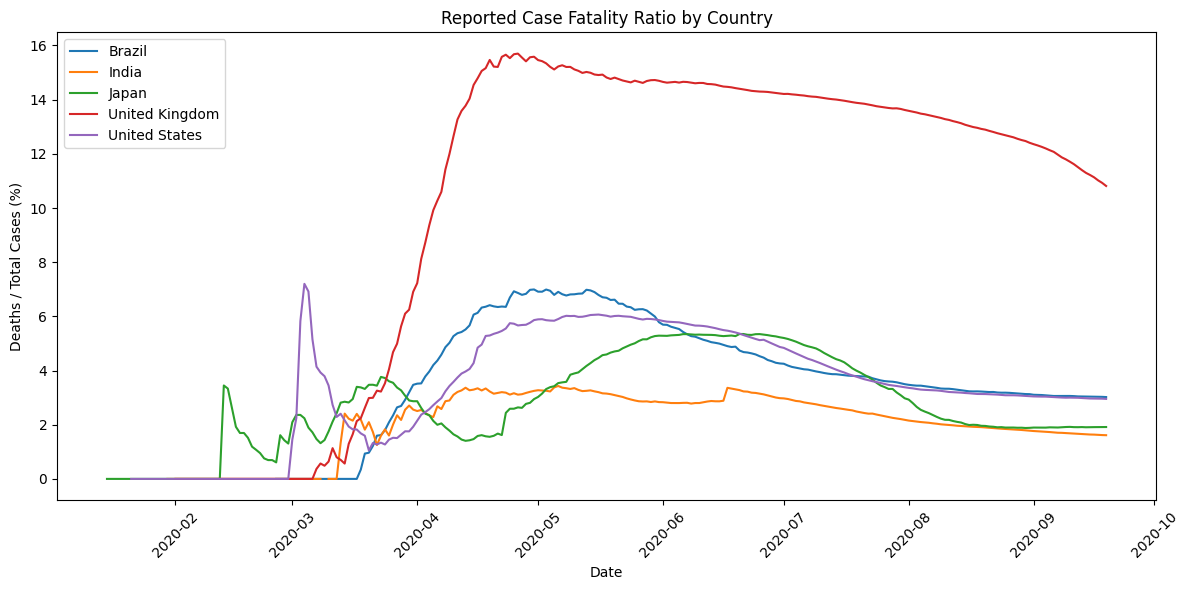

All 5 charts created 


In [ ]:
plt.figure(figsize=(12, 6))
for country, group in covid.groupby("location"):
    plt.plot(group["date"], group["case_fatality_ratio_pct"], label=country)

plt.title("Reported Case Fatality Ratio by Country")
plt.xlabel("Date")
plt.ylabel("Deaths / Total Cases (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


print("All 5 charts created ")

In [ ]:
latest = (
    covid.sort_values("date")
    .groupby("location")
    .tail(1)
    .copy()
)

summary_columns = [
    "location",
    "date",
    "total_cases",
    "total_deaths",
    "total_cases_per_million",
    "total_deaths_per_million",
    "case_fatality_ratio_pct"
]

print("Latest available figures for each country:")
display(latest[summary_columns].sort_values("total_cases", ascending=False))

print("\nPeak 7-day average of new cases by country:")
peak_cases = (
    covid.groupby("location")["new_cases_7day_avg"]
    .max()
    .sort_values(ascending=False)
    .reset_index(name="Peak 7-Day Average Cases")
)
display(peak_cases)

print("\nPeak 7-day average of new deaths by country:")
peak_deaths = (
    covid.groupby("location")["new_deaths_7day_avg"]
    .max()
    .sort_values(ascending=False)
    .reset_index(name="Peak 7-Day Average Deaths")
)
display(peak_deaths)


Latest available figures for each country:


,location,date,total_cases,total_deaths,total_cases_per_million,total_deaths_per_million,case_fatality_ratio_pct
1319,United States,2020-09-19,6724667.0,198589.0,20316.052,599.962,2.953143
527,India,2020-09-19,5308014.0,85619.0,3846.375,62.043,1.613014
263,Brazil,2020-09-19,4495183.0,135793.0,21147.890,638.847,3.020856
1055,United Kingdom,2020-09-19,385936.0,41732.0,5685.060,614.736,10.813192
791,Japan,2020-09-19,78073.0,1495.0,617.293,11.820,1.914875



Peak 7-day average of new cases by country:


,location,Peak 7-Day Average Cases
0,India,93198.571429
1,United States,67373.571429
2,Brazil,46393.000000
3,United Kingdom,4846.142857
4,Japan,1581.000000



Peak 7-day average of new deaths by country:


,location,Peak 7-Day Average Deaths
0,United States,2715.142857
1,India,1168.000000
2,Brazil,1096.714286
3,United Kingdom,942.428571
4,Japan,29.000000


Five key insights from your results

1. The United States recorded the highest cumulative case count among the five countries.
By 19 September 2020, the United States had approximately 6.72 million reported cases and 198,589 reported deaths, the highest totals in this comparison.


2. India had the highest peak in its seven-day average of new cases.
India's peak was approximately 93,199 new cases per day, exceeding the peak averages for the United States and Brazil in this dataset.


3. The United States had the highest peak seven-day average of daily deaths.
Its peak average was approximately 2,715 deaths per day, compared with about 1,168 in India and 1,097 in Brazil.


4. Population-adjusted case rates changed the comparison.
Brazil had approximately 21,148 reported cases per million people, slightly above the United States at 20,316. This shows why population-adjusted measures are useful alongside total case counts.


5. The United Kingdom had the highest reported case fatality ratio.
Its ratio was approximately 10.81%, compared with around 3.02% in Brazil and 2.95% in the United States. This is a ratio of reported deaths to reported cases—not a direct measure of an individual's risk of dying. Differences in testing, reporting, and timing can affect comparisons.

In [ ]:
!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import cm

pdf_file = "COVID19_Executive_Summary.pdf"

doc = SimpleDocTemplate(
    pdf_file,
    pagesize=A4,
    rightMargin=1.6*cm,
    leftMargin=1.6*cm,
    topMargin=1.4*cm,
    bottomMargin=1.4*cm
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="SmallText",
    parent=styles["BodyText"],
    fontSize=9,
    leading=12,
    spaceAfter=5
))

story = []

story.append(Paragraph(
    "COVID-19 Global Impact Analysis",
    styles["Title"]
))
story.append(Paragraph(
    "Executive Summary | 31 December 2019 – 19 September 2020",
    styles["Heading2"]
))
story.append(Spacer(1, 8))

story.append(Paragraph(
    "Objective",
    styles["Heading2"]
))
story.append(Paragraph(
    "This project examines reported COVID-19 cases and deaths across India, "
    "the United States, the United Kingdom, Brazil, and Japan. The analysis "
    "uses daily data, seven-day rolling averages, population-adjusted case "
    "rates, and reported case fatality ratios.",
    styles["SmallText"]
))

story.append(Paragraph("Key Findings", styles["Heading2"]))

insights = [
    "The United States recorded the highest cumulative totals in this comparison, "
    "with approximately 6.72 million cases and 198,589 deaths by 19 September 2020.",
    "India had the highest peak seven-day average of new cases, at approximately "
    "93,199 cases per day.",
    "The United States had the highest peak seven-day average of new deaths, "
    "at approximately 2,715 deaths per day.",
    "Brazil recorded approximately 21,148 cases per million people, slightly "
    "above the United States at 20,316 per million.",
    "The United Kingdom had the highest reported case fatality ratio, around "
    "10.81%. Differences in testing, reporting, and timing limit direct comparisons."
]

for i, insight in enumerate(insights, 1):
    story.append(Paragraph(f"{i}. {insight}", styles["SmallText"]))

story.append(Paragraph("Methodology", styles["Heading2"]))
story.append(Paragraph(
    "The dataset was filtered to five countries, dates were converted to "
    "datetime format, and duplicate country-date records were checked. "
    "Seven-day rolling averages were calculated using seven daily observations. "
    "Missing values were retained where information was unavailable. The "
    "case fatality ratio was calculated as total reported deaths divided by "
    "total reported cases, multiplied by 100.",
    styles["SmallText"]
))

story.append(Paragraph("Conclusion and Limitations", styles["Heading2"]))
story.append(Paragraph(
    "The selected countries experienced different reported case and death "
    "patterns during the period studied. Total counts and population-adjusted "
    "rates provide complementary perspectives. Findings are limited to the "
    "available data through 19 September 2020 and may be affected by differences "
    "in testing and reporting. The dataset does not contain vaccination data, "
    "so no conclusions about vaccination effects are made.",
    styles["SmallText"]
))

story.append(Spacer(1, 6))
story.append(Paragraph(
    "Tools Used: Python, Pandas, Matplotlib, Google Colab",
    styles["SmallText"]
))

doc.build(story)

print("PDF created:", pdf_file)


PDF created: COVID19_Executive_Summary.pdf
